###Project Name: House Price and Category Prediction
### Models: Linear Regression and Random Forest Classifier

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (506, 14)


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [3]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())


Column names:
['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'medv']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB

Missing values:
crim       0
zn         0
indus      0
chas       0
nox        0
rm         

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


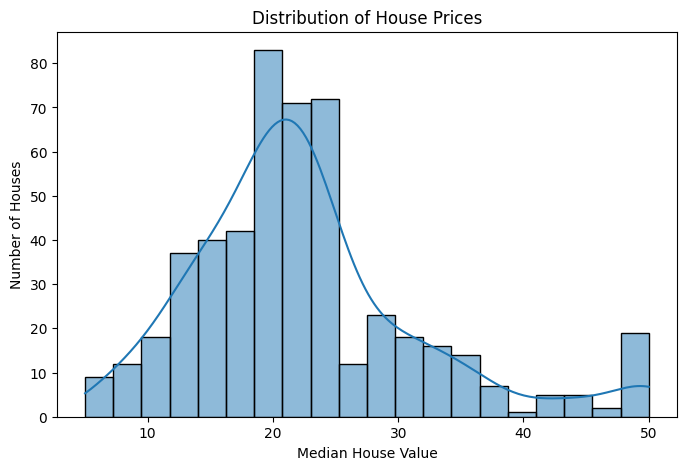

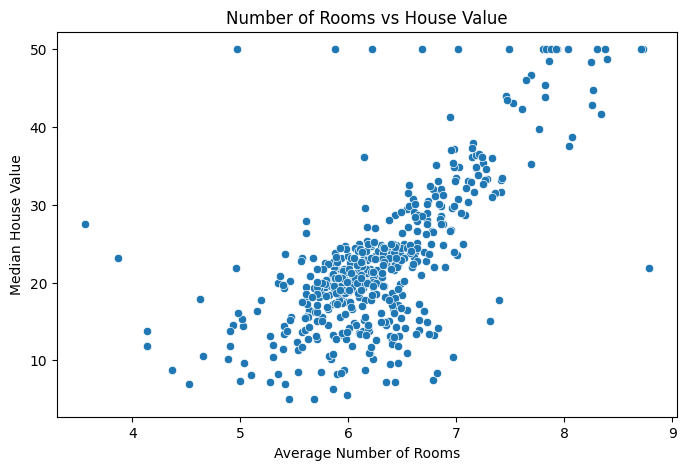

In [4]:

# Distribution of house prices
plt.figure(figsize=(8, 5))
sns.histplot(df["medv"], bins=20, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Median House Value")
plt.ylabel("Number of Houses")
plt.show()

# Relationship between rooms and house prices
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="rm", y="medv")
plt.title("Number of Rooms vs House Value")
plt.xlabel("Average Number of Rooms")
plt.ylabel("Median House Value")
plt.show()


In [5]:

# Remove rows with missing target prices
df = df.dropna(subset=["medv"]).copy()

# Remove price outliers using IQR
Q1 = df["medv"].quantile(0.25)
Q3 = df["medv"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df = df[(df["medv"] >= lower) & (df["medv"] <= upper)].copy()

# Input features and continuous target
X = df.drop("medv", axis=1)
y = df["medv"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Fill missing input features using training data only
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

# Define Low, Medium, and High categories
low_threshold = y_train.quantile(1/3)
high_threshold = y_train.quantile(2/3)

def make_category(prices):
    return np.where(
        prices <= low_threshold, "Low",
        np.where(prices <= high_threshold, "Medium", "High")
    )

y_train_category = make_category(y_train)
y_test_category = make_category(y_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Low threshold:", round(low_threshold, 2))
print("High threshold:", round(high_threshold, 2))
print("Preprocessing completed!")


Training records: 372
Testing records: 94
Low threshold: 18.5
High threshold: 23.03
Preprocessing completed!


In [6]:

# Linear Regression predicts continuous house prices
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [7]:

# Random Forest predicts Low, Medium, or High house value
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

rf_model.fit(X_train, y_train_category)

print("Random Forest Classifier trained successfully!")


Random Forest Classifier trained successfully!


In [8]:

# Predict house prices
price_predictions = linear_model.predict(X_test)

# Evaluate regression model
r2 = r2_score(y_test, price_predictions)
mae = mean_absolute_error(y_test, price_predictions)

print("Linear Regression Results")
print("R-squared (R²):", round(r2, 3))
print("Mean Absolute Error:", round(mae, 3))


Linear Regression Results
R-squared (R²): 0.752
Mean Absolute Error: 2.231


In [9]:

# Predict house categories
category_predictions = rf_model.predict(X_test)

# Calculate classification accuracy
accuracy = accuracy_score(y_test_category, category_predictions)

print("Random Forest Classification Results")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test_category,
    category_predictions,
    zero_division=0
))


Random Forest Classification Results
Accuracy: 76.6 %

Classification Report:
              precision    recall  f1-score   support

        High       0.81      0.79      0.80        28
         Low       0.90      0.77      0.83        35
      Medium       0.62      0.74      0.68        31

    accuracy                           0.77        94
   macro avg       0.78      0.77      0.77        94
weighted avg       0.78      0.77      0.77        94



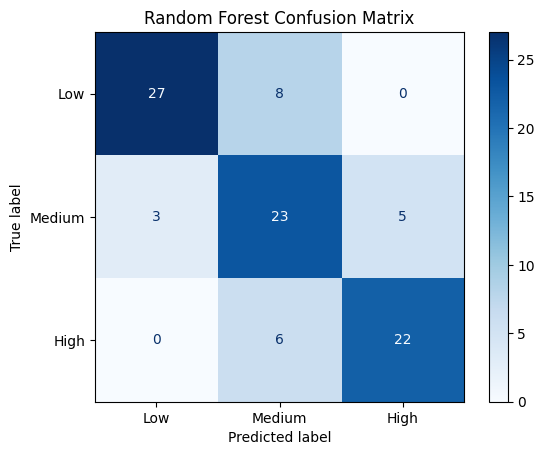

In [10]:

cm = confusion_matrix(
    y_test_category,
    category_predictions,
    labels=["Low", "Medium", "High"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

display.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()


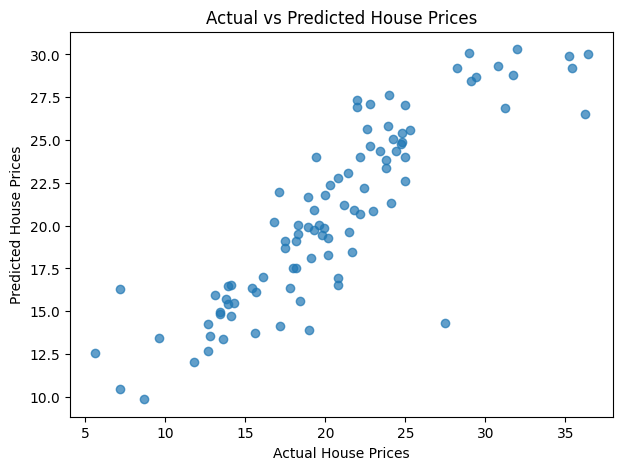

In [11]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, price_predictions, alpha=0.7)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()


In [12]:

print("FINAL PROJECT RESULTS")
print("---------------------")
print("Linear Regression R²:", round(r2, 3))
print("Linear Regression MAE:", round(mae, 3))
print("Random Forest Accuracy:", round(accuracy * 100, 2), "%")

print("\nConclusion:")
print("Linear Regression was used to predict numerical house prices.")
print("Random Forest was used to classify houses into three value categories.")
print("Both models were evaluated using appropriate performance metrics.")


FINAL PROJECT RESULTS
---------------------
Linear Regression R²: 0.752
Linear Regression MAE: 2.231
Random Forest Accuracy: 76.6 %

Conclusion:
Linear Regression was used to predict numerical house prices.
Random Forest was used to classify houses into three value categories.
Both models were evaluated using appropriate performance metrics.
